# 8.1 Human-AI Collaboration

*Note*: If you are on Mac and receive the error "You are running 32-bit Python on a 64-bit OS
", try running "brew install libomp" in your Mac console (make sure homebrew is installed on your Mac) and restart the kernel.

In [1]:
# %pip install xgboost catboost shap

In [2]:
# General data science packages
import xgboost
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import *
import numpy as np

# SHAP package
import shap
shap.initjs() # Initializes the JS Library

## California Housing Dataset
In this exercise, we will use the [California Housing Dataset](https://www.kaggle.com/datasets/camnugent/california-housing-prices). It comprises over 20'000 districts (called "blocks" in the dataset) in California with information about their houses. It is usually used to predict the median house value in a specific block.
Load the dataset and explore the features.

1. `longitude`: A measure of how far west a house is; a higher value is farther west

2. `latitude`: A measure of how far north a house is; a higher value is farther north

3. `housingMedianAge`: Median age of a house within a block; a lower number is a newer building

4. `totalRooms`: Total number of rooms within a block

5. `totalBedrooms`: Total number of bedrooms within a block

6. `population`: Total number of people residing within a block

7. `households`: Total number of households, a group of people residing within a home unit, for a block

8. `medianIncome`: Median income for households within a block of houses (measured in tens of thousands of US Dollars)

9. `medianHouseValue`: Median house value for households within a block (measured in US Dollars)

10. `oceanProximity`: Location of the house w.r.t ocean (4 means coastline, 0 means mainland)

In [ ]:
from pathlib import Path

candidate_paths = [
  parent / "data" / "8_housing.csv"
  for parent in (Path.cwd(), *Path.cwd().parents)
]


data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find data/8_housing.csv in the repository.")

print(f"Loading: {data_path.resolve()}")

In [4]:
housing_dataset= pd.read_csv(data_path)
housing_dataset.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Visualize all features of the dataset by displaying them as histograms with the `matplotlib.pyplot` library.

In [5]:
# Preprocess ocean proximity to numerical values
housing_dataset['ocean_proximity'] = housing_dataset['ocean_proximity'].astype('category').cat.codes

In [6]:
# delete NaN values
housing_dataset = housing_dataset.dropna()

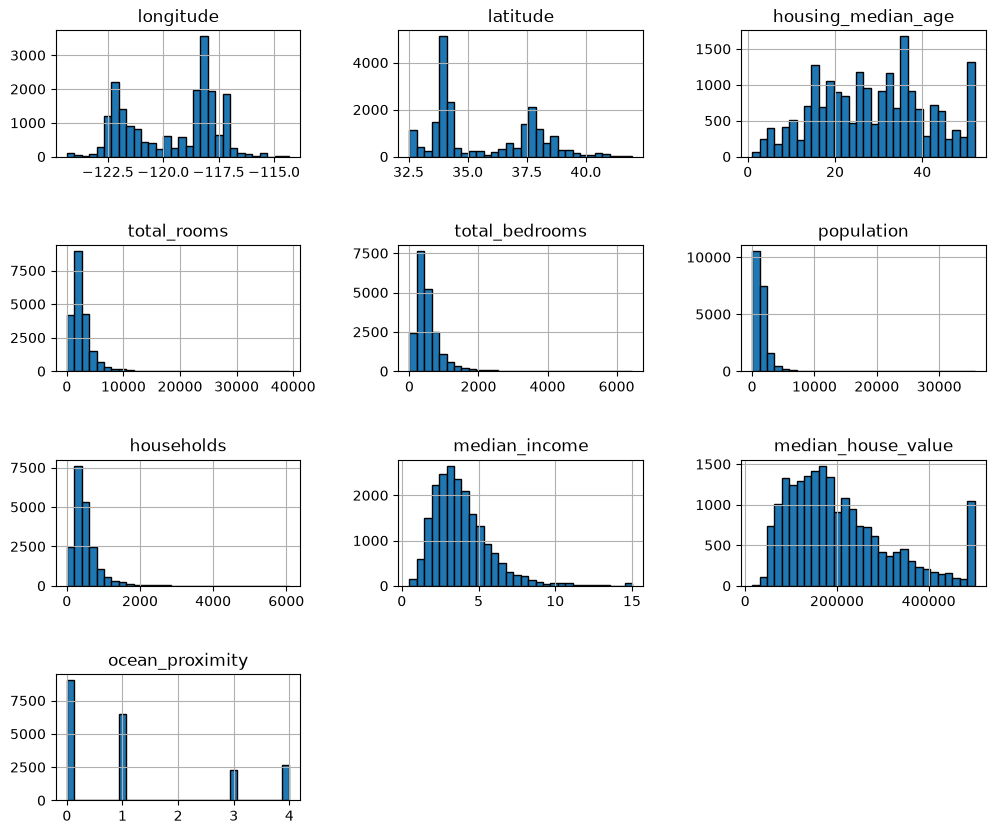

In [7]:
housing_dataset.hist(figsize=(12, 10), bins=30, edgecolor="black")
plt.subplots_adjust(hspace=0.7, wspace=0.4)

What is happening at the $500'000 mark?
During data collection, the median house value of highly valuable blocks was capped at the mark of $500'000 for privacy reasons.

## Human-in-the-Loop

Today you are the human-in-the-loop. Your task is to accurately responsible for accurate estimate median house values of blocks in California. In order to support your estimations, you train a simple model and use its predictions to estimate house values.

In [8]:
# Extract the Features X (as a dataframe with the correct feature names) and the target Y
X = housing_dataset.drop('median_house_value', axis=1)
y = housing_dataset['median_house_value']

In [9]:
# train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
# Train an XGBoost Regressor model
model = xgboost.XGBRegressor().fit(X_train, y_train)

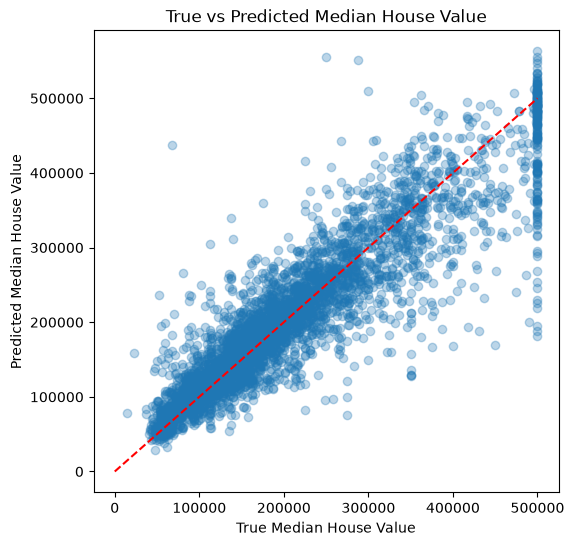

Model R2 on test set:  0.8254430494544778


In [11]:
# Quick evaluation on the test set
y_pred = model.predict(X_test)
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, 500000], [0, 500000], color='red', linestyle='--')
plt.xlabel("True Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("True vs Predicted Median House Value")
plt.show()
print("Model R2 on test set: ", model.score(X_test, y_test))

Looks like the model is struggling to predict the blocks whose values were capped at $500'000.

### **Task: Human-in-the-Loop**

1. Print a random data point. What additional features (that you can engineer from the existing ones) would be helpful? Feel free to compute them to support your estimation.

In [12]:
# Select an arbitrary data point from the dataset
index = 42
data_point = X_test.iloc[[index]]
print(data_point)

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
10362     -117.7     33.62                16.0       9653.0          2000.0   

       population  households  median_income  ocean_proximity  
10362      4732.0      1922.0         3.7361                0  


In [13]:
# helpful engineered features
average_rooms = X_test['total_rooms'] / X_test['households']
average_bedrooms = X_test['total_bedrooms'] / X_test['households']
population_per_household = X_test['population'] / X_test['households']
print("Average rooms per household: ", average_rooms.iloc[index])
print("Average bedrooms per household: ", average_bedrooms.iloc[index])
print("Population per household: ", population_per_household.iloc[index])

Average rooms per household:  5.022372528616025
Average bedrooms per household:  1.0405827263267429
Population per household:  2.4620187304890737


2. Try to guess the house value.

In [14]:
# Enter your guess
my_first_guess = 500000

3. Check the model prediction and adapt your guess if you want.

In [15]:
# Use the XGBoost Regressor model to predict the house value
house_value = model.predict(data_point)[0]
print("Predicted median house value: "f"${house_value:.0f}")

Predicted median house value: $168007


In [16]:
# Enter your second guess
my_second_guess = 200000

4. Check how far you were off. Are you satisfied with your prediction? What biases could have been at play here?

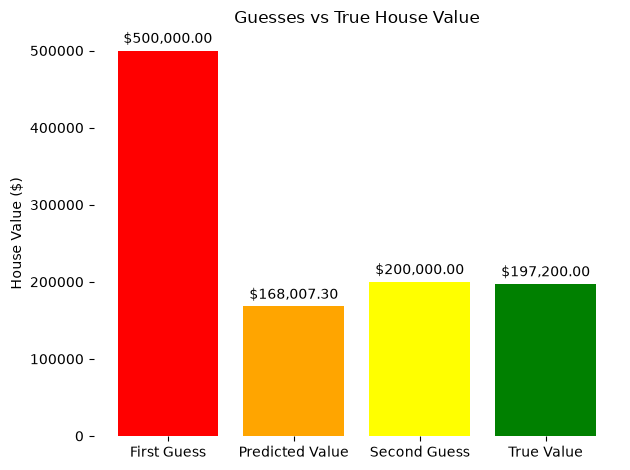

In [17]:
# Data for the bar chart
labels = ["First Guess", "Predicted Value", "Second Guess", "True Value"]
values = [my_first_guess, house_value, my_second_guess, y_test.iloc[index]]  # Values for each bar
colors = ['red', 'orange', 'yellow', 'green']  # Different colors for each bar

# Create the bar chart
plt.bar(labels, values, color=colors)
plt.ylabel('House Value ($)')
plt.title('Guesses vs True House Value')

# Annotate the values on bars
for i, v in enumerate(values):
  plt.text(i, v + 10000, f"${v:,.2f}", ha='center')

# Remove bounding box (spines)
for spine in plt.gca().spines.values():
  spine.set_visible(False)

# Show plot
plt.tight_layout()
plt.show()

## Feature Importance with SHAP
[SHAP (SHapley Additive exPlanations)](https://github.com/slundberg/shap) is a game theoretic approach to approximate the feature importance of any machine learning model output. It connects optimal merit attribution with local explanations using [Shapley values](https://en.wikipedia.org/wiki/Shapley_value) from game theory. This means that if a feature has a (relatively) high SHAP value, we can assume that it has distinctively driven the model prediction.

### **TASK: Raw Feature Importance**
Display the raw content of the SHAP values for the instance selected above. What information is contained?


In [18]:
# Explain the model's predictions using SHAP's Explainer module
explainer = shap.Explainer(model)

# Calculate the SHAP values for all instances in X_test
shap_values = explainer(X_test)

In [19]:
# Select index from above
shap_values[index]

.values =
array([-65216.816  ,  48090.21   , -18837.055  ,  30432.766  ,
          137.44751, -29916.717  ,  -2017.0503 , -11394.788  ,
        10096.259  ], dtype=float32)

.base_values =
np.float32(206633.05)

.data =
array([-1.1770e+02,  3.3620e+01,  1.6000e+01,  9.6530e+03,  2.0000e+03,
        4.7320e+03,  1.9220e+03,  3.7361e+00,  0.0000e+00])

**Your answer**: 
- `.values` contains the SHAP values, i.e., the feature importance scores of the features in the test set
- `.base_values` represents the average predicted house price across the entire training set, i.e., the naive starting point of each prediction
- `.data` contains the feature values for the selected block sample

### Local Explanations (for Individual Predictions)

Use a [Waterfall Plot](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/waterfall.html) to explain the prediction of the first instance. It shows features each contributing to push the model output from the base value (the average model output over the training dataset we passed) to the model output. Features pushing the prediction higher are shown in red, those pushing the prediction lower are in blue.

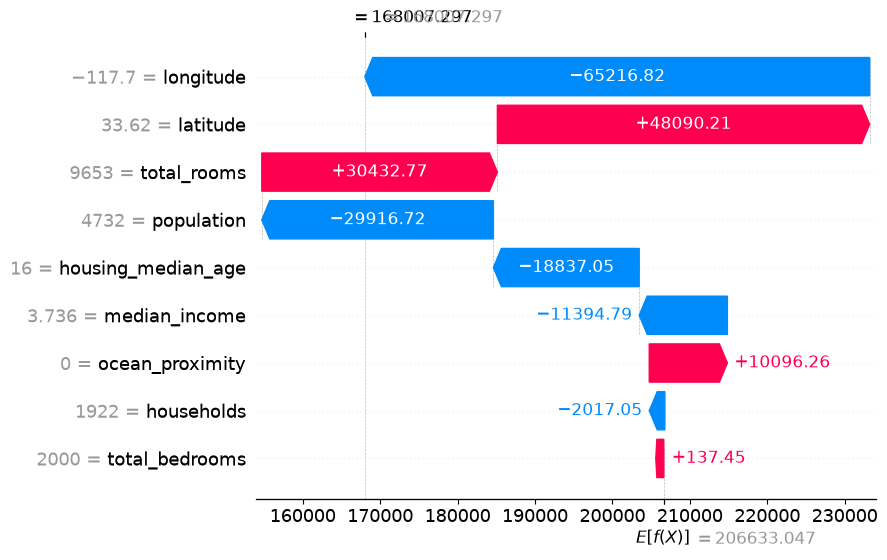

In [20]:
# Visualize the first prediction's explanation with a waterfall plot:
shap.plots.waterfall(shap_values[index])

Description of components:
- $E[f(X)]$: This is the **average prediction** the model would make if it knew nothing about the specific block. Before seeing any features, the model assumes the mean value of the entire training dataset, which is $206'634.
- $f(x)$: This is the **final prediction** of the model based on the features from this specific block.
- Y-axis: Here are the features of the dataset listed with the raw values for this specific block.
- Red and blue bars: Each bar represents how a specific feature "moved" the price away from the average, with red bars having **positive impact** and blue bars having **negative impact**.

Another way to visualize the same explanation is to use a [force plot](https://shap.readthedocs.io/en/latest/generated/shap.plots.force.html) (these were introduced in the following [Nature BME paper](https://rdcu.be/baVbR)):

In [21]:
# Visualize the first prediction's explanation with a force plot:
shap.plots.force(shap_values[0])

### **TASK: Interpretation of Local Explanations**
How do you interpret the local explanation for the first block?

**Your Interpretation:** 
Always keep in mind that this is only a coarse abstraction of what actually happens in the model, but you can read the plot from the bottom up as follows:
- The model starts at the average price of $206'634
- The model sees the number of households (1922) and adjusts the the prediction by -$3'000
- The model sees the median income (3.736) and adjusts the the prediction by another -$3.5'000
- ...
- For this particular block, the median income has the highest impact on the prediction of the median house value.

### Global Explanations (for Model Behavior)

To get an overview of which features are most important for a model we can plot the SHAP values of every feature for every sample we can use a [beeswarm plot](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/beeswarm.html). The plot below sorts features by the sum of SHAP value magnitudes over all samples, and uses SHAP values to show the distribution of the impacts each feature has on the model output. The color represents the feature value (red high, blue low).



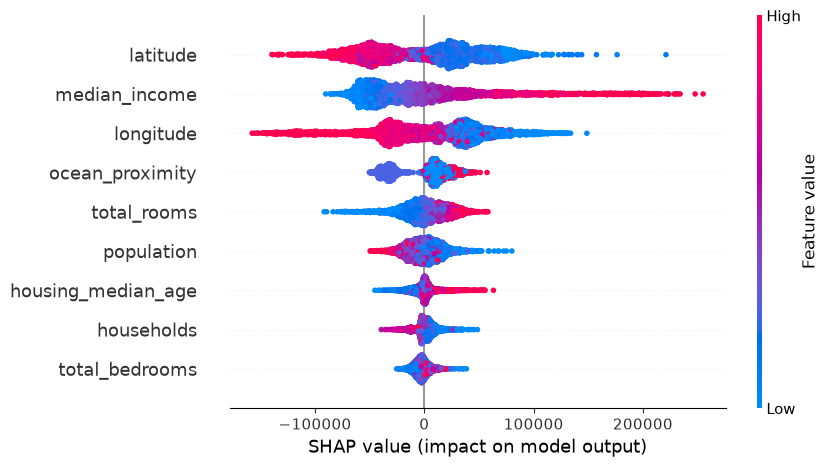

In [22]:
# summarize the effects of all the features
shap.plots.beeswarm(shap_values)

We can also just take the mean absolute value of the SHAP values for each feature to get a standard [bar plot](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/bar.html) (produces stacked bars for multi-class outputs):

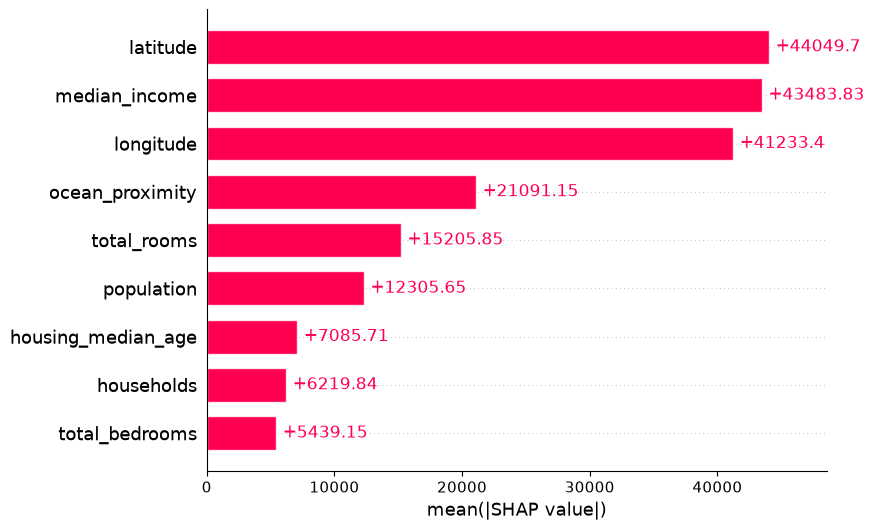

In [23]:
# summarize the absolute effects of all the features
shap.plots.bar(shap_values)

However, these are just absolute mean values which might not be representative of all data points. Instead, we can create cohorts to compare SHAP differences between certain subsections.

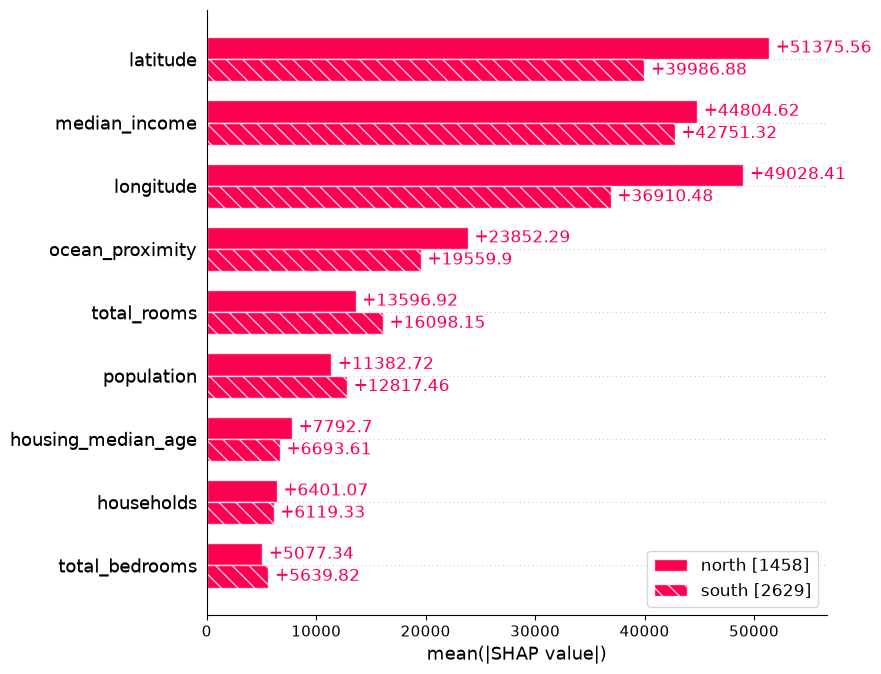

In [24]:
# divide block groups into north and south
latitude = ["north" if (shap_values[i, "latitude"].data > 37 ) else "south" for i in range(shap_values.shape[0])]
shap.plots.bar(shap_values.cohorts(latitude).abs.mean(0))

### **TASK: Interpretation of Global Explanations**
How do you interpret the global explanation for the first block? What is the difference between north and south blocks?

**Your Interpretation:** It seems like the median income and the geographic location (latitude + longitude) of a block determine the median house value. We can also see that for southern block groups, features other than latitude are more relevant, for example number of rooms and number of household members.

## Human-in-the-Loop with SHAP Support

### **Task: Human-in-the-Loop with SHAP Support**
Now, try to predict mean house values again--this time supported not only by predictions but also by explanations. 

1. Print a data point (and additionally engineered features if you want) and try to guess the house value.

In [25]:
# Select another arbitrary data point from the dataset
index_2 = 420
data_point_2 = X_test.iloc[[index_2]]
print(data_point_2)
print("Average rooms per household: ", average_rooms.iloc[index_2])
print("Average bedrooms per household: ", average_bedrooms.iloc[index_2])
print("Population per household: ", population_per_household.iloc[index_2])

      longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
4937    -118.26     33.99                47.0       1865.0           465.0   

      population  households  median_income  ocean_proximity  
4937      1916.0       438.0         1.8242                0  
Average rooms per household:  4.257990867579909
Average bedrooms per household:  1.0616438356164384
Population per household:  4.3744292237442925


2. Try to guess the house value.

In [26]:
# Enter your first guess
my_first_guess_2 = 150000

3. Check the model prediction and the local explanation. Adapt your guess if you want.

Predicted house value: $104930.42


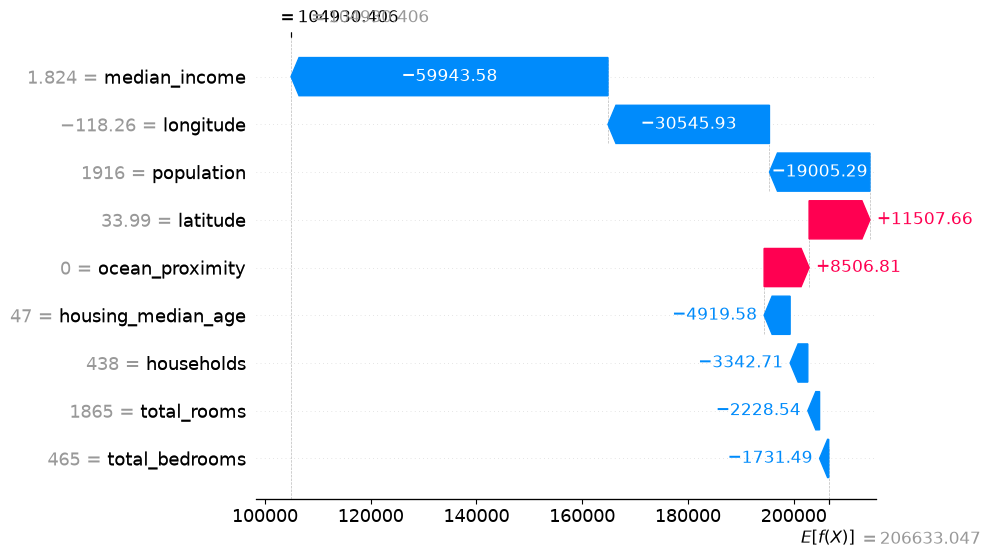

In [27]:
# Use the XGBoost Regressor model to predict the house value
house_value = model.predict(data_point_2)[0]
print("Predicted house value: "f"${house_value:.2f}")

# Use SHAP to explain the model's prediction
shap.plots.waterfall(shap_values[index_2])

In [28]:
# Enter your second guess
my_second_guess_2 = 100000

4. Check how far you were off. Are you satisfied with your prediction?

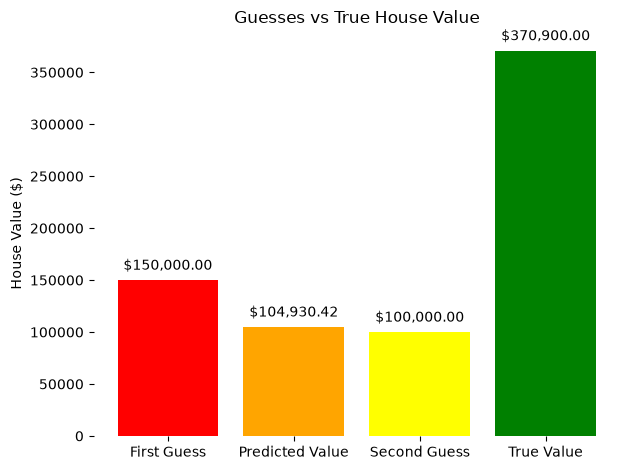

In [29]:
# Data for the bar chart
labels = ["First Guess", "Predicted Value", "Second Guess", "True Value"]
values = [my_first_guess_2, house_value, my_second_guess_2, y[index_2]]  # Values for each bar
colors = ['red', 'orange', 'yellow', 'green']  # Different colors for each bar

# Create the bar chart
plt.bar(labels, values, color=colors)
plt.ylabel('House Value ($)')
plt.title('Guesses vs True House Value')

# Annotate the values on bars
for i, v in enumerate(values):
  plt.text(i, v + 10000, f"${v:,.2f}", ha='center')

# Remove bounding box (spines)
for spine in plt.gca().spines.values():
  spine.set_visible(False)

# Show plot
plt.tight_layout()
plt.show()

## Discussion

### **TASK: Limitations and Benefits of SHAP Explanations**
Discuss the limitations and benefits of the SHAP explanations:
- How did you make use of the SHAP explanations? 
- Are the SHAP explanations plausible? Are they correct?
- Is there a pattern that the SHAP explanations did not pick up?
- Which additional information/explanations would have been helpful to you as a human-in-the-loop?

If you need help, open the following hints by clicking on the text.

**Your discussion:**

### Solution: Background Information on California Housing Prices

<details>
<summary>[Click HERE to toggle the 1st hint]</summary>

California is located between the following coordinates:
- Latitude: 32° 30' (i.e, South) N to 42° N (i.e, North)
- Longitude: -124° 24' W (i.e., West) to -114° 8' (i.e., East) W. 

</details>

<details>
<summary>[Click HERE to toggle the 2nd hint]</summary>

Income in the California is (approximately) distributed as follows:
<img src="images/income.png" width="500"/>

</details>

Use [seaborn](https://seaborn.pydata.org/generated/seaborn.scatterplot.html#seaborn.scatterplot) package to plot the spatial location of all instances (i.e., `Longitude` and `Latitude`) as well as their median house value (i.e., `MedHouseVal`) to support your discussion.

Hint: Use longitude and latutide for the x and y coordindates and use the median house value for the size or hue.

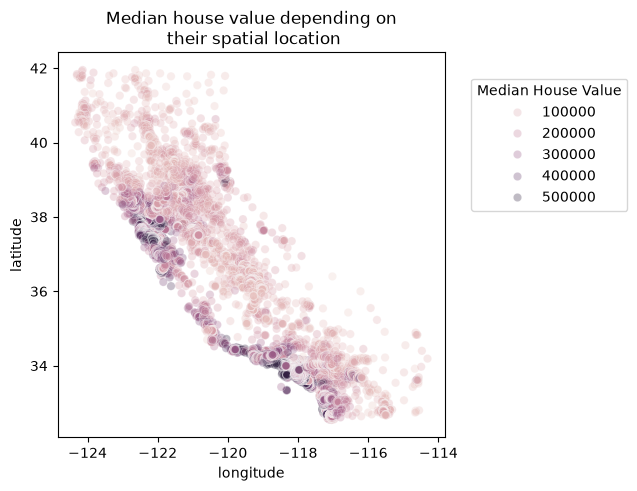

In [30]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=housing_dataset, x="longitude", y="latitude", hue="median_house_value", alpha=0.3)
plt.legend(title="Median House Value", bbox_to_anchor=(1.05, 0.95), loc="upper left")
plt.title("Median house value depending on\n their spatial location")
plt.show()

We can also visualize this more precisely in an interactive map where bigger circles mean higher median house value.

In [ ]:
# %pip install folium

In [32]:
import folium

# Initialize a map
map = folium.Map(location=[36.7783, -119.4179], zoom_start=6)

# Sample blocks for better performance
data = pd.DataFrame(X_test)
data['median_house_value'] = y_test.values
sample = data.sample(1000)

# Iterate through the dataset and add markers
for index, row in sample.iterrows():
  # Create an HTML string for the popup
  popup_html = f"""
  <strong>Median House Value:</strong> <span style='color:red;'>{row['median_house_value']:.2f}</span><br>
  <strong>Median Income:</strong> {row['median_income']:.2f}<br>
  <strong>Median House Age:</strong> {row['housing_median_age']:.2f}<br>
  <strong>Total Rooms:</strong> {row['total_rooms']:.2f}<br>
  <strong>Total Bedrooms:</strong> {row['total_bedrooms']:.2f}<br>
  <strong>Population:</strong> {row['population']:.2f}<br>
  <strong>Total Households:</strong> {row['households']:.2f}<br>
  """
  popup = folium.Popup(html=popup_html, max_width=300)

  # Add a marker to the map
  folium.CircleMarker(
  [row['latitude'], row['longitude']],
  radius=row['median_house_value']/100000,
  color='blue',
  fill=True,
  fill_color='grey',
  fill_opacity=0.3,
  popup=popup
  ).add_to(map)


from IPython.display import display

display(map)

**Observation:** It looks like the high-valued houses are located on the coast, where the big cities from California are located: San Diego, Los Angeles, San Jose, or San Francisco.